# MGWR + Robust (M-estimator) — Persentase Penduduk Miskin, Pulau Jawa

**Model:** `Y (Penduduk Miskin, %) ~ RLS + PDRB + UMK + TPT`, 119 kab/kota. Tiap koefisien punya bandwidth sendiri (MGWR) dan diestimasi dengan pembobot robust (Huber utama, Tukey sebagai uji sensitivitas).

**Alur:** (1) data & koordinat → (2) eksplorasi → (3) uji asumsi (multikolinearitas, normalitas, heteroskedastisitas, pencilan, autokorelasi spasial) → (4) MGWR robust → (5) ringkasan model → (6) uji heterogenitas spasial → (7) koefisien lokal, uji-t, peta → (8) diagnostik akhir & pencilan.

| No | Asumsi / syarat | Uji | Keputusan |
|---|---|---|---|
| 1 | Respon kontinu | Histogram, skewness | Persentase kontinu → MGWR (bukan NB) |
| 2 | Tidak ada multikolinearitas serius | VIF, condition index | VIF < 5 (aman), > 10 (serius) |
| 3 | Galat berdistribusi normal | Shapiro-Wilk, Jarque-Bera | Tidak normal → pertimbangan robust |
| 4 | Homoskedastisitas | Breusch-Pagan, Koenker | Tolak H0 → ada heterogenitas varians |
| 5 | Tidak ada pencilan berpengaruh | Residual terstudentisasi, leverage, Cook's D | Ada pencilan → estimasi robust (M-estimator) |
| 6 | Galat tidak berautokorelasi spasial | Moran's I residual | Signifikan → ada struktur spasial |
| 7 | Ada nonstasioneritas spasial | Uji Monte Carlo, bandwidth per variabel | Alasan memakai model lokal multiskala |
| 8 | Koordinat titik, jarak Euclid | Koordinat dalam km | Kernel bisquare adaptif, bandwidth = jumlah tetangga |

**Data:** satu file berisi `Y` (persen miskin), `RLS`, `PDRB`, `UMK`, `TPT`, `lon`, `lat`, `x_km`, `y_km`. Model OLS di bagian 3b hanya dipakai sebagai alat uji asumsi, bukan sebagai model pembanding.

**Catatan implementasi:** MGWR dan M-estimator ditulis sendiri (backfitting + IRLS) karena paket `mgwr` tidak menyediakan estimasi robust. Uji-t lokal bersifat pendekatan.

In [17]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings('ignore')
try: get_ipython().run_line_magic('matplotlib', 'inline')
except NameError: pass
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25})

## 1. Parameter

In [18]:
FILE_DATA  = 'SPASIAL ARTIKEL PULAU JAWA.xlsx'   # sesuaikan dengan nama file Anda (satu file: Y, X, lon, lat, x_km, y_km)
Y_COL      = 'Y'                                 # persentase penduduk miskin
Y_LABEL    = 'Penduduk Miskin (%)'
X_COLS     = ['RLS', 'PDRB', 'UMK', 'TPT']
XY_COLS    = ['x_km', 'y_km']                    # koordinat terproyeksi (km) untuk jarak Euclid
LOG_VARS   = []                  # contoh: ['PDRB', 'UMK'] bila ingin transformasi log
K_NEIGH    = 5                   # matriks bobot Moran's I: k tetangga terdekat, row-standardized
BW_GRID    = [10, 15, 20, 25, 30, 40, 50, 60, 80, 100, 119]   # kandidat bandwidth adaptif (jumlah tetangga)
C_HUBER    = 1.345               # konstanta Huber (Tukey memakai 4.685)
NPERM      = 999                 # permutasi Moran's I
NSIM_MC    = 99                  # simulasi uji Monte Carlo heterogenitas
OUT_DIR    = os.environ.get('OUT_DIR', 'hasil_mgwr')
os.makedirs(OUT_DIR, exist_ok=True)

## 2. Data dan koordinat

In [19]:
df = pd.read_excel(FILE_DATA); df.columns = [str(c).strip() for c in df.columns]

assert df[[Y_COL] + X_COLS + XY_COLS].notna().all().all(), 'Ada data kosong'
assert not df['Kabupaten/Kota'].duplicated().any(), 'Ada nama kab/kota ganda'
print('N =', len(df), '| provinsi:', df['Provinsi'].nunique(), '| missing =', int(df[[Y_COL] + X_COLS + XY_COLS].isna().sum().sum()))
for v in LOG_VARS: df[v] = np.log(df[v])

n = len(df); k = len(X_COLS) + 1; names = ['Intercept'] + X_COLS
y = df[Y_COL].values.astype(float)
Xraw = df[X_COLS].values.astype(float)
X = np.column_stack([np.ones(n), (Xraw - Xraw.mean(0)) / Xraw.std(0)])     # prediktor distandarisasi
coords = df[XY_COLS].values
Dm = np.sqrt(((coords[:, None, :] - coords[None, :, :]) ** 2).sum(-1))     # jarak Euclid (km)
tss = ((y - y.mean()) ** 2).sum()
df[[Y_COL] + X_COLS].describe().round(2)

N = 119 | provinsi: 6 | missing = 0


,Y,RLS,PDRB,UMK,TPT
count,119.00,119.00,119.00,119.00,119.00
mean,8.56,8.88,84425.36,3153008.06,4.65
std,3.51,1.65,115803.95,1089084.80,1.81
min,2.31,5.19,24047.00,2170475.00,1.33
25%,6.08,7.73,34937.00,2370450.50,3.29
50%,8.40,8.31,44917.00,2610224.00,4.29
75%,10.68,10.09,77962.00,3579006.50,6.08
max,20.61,12.13,949177.00,5690753.00,8.78


## 3. Eksplorasi data

Skewness : {'Y': 0.6, 'RLS': 0.46, 'PDRB': 4.73, 'UMK': 1.12, 'TPT': 0.33}


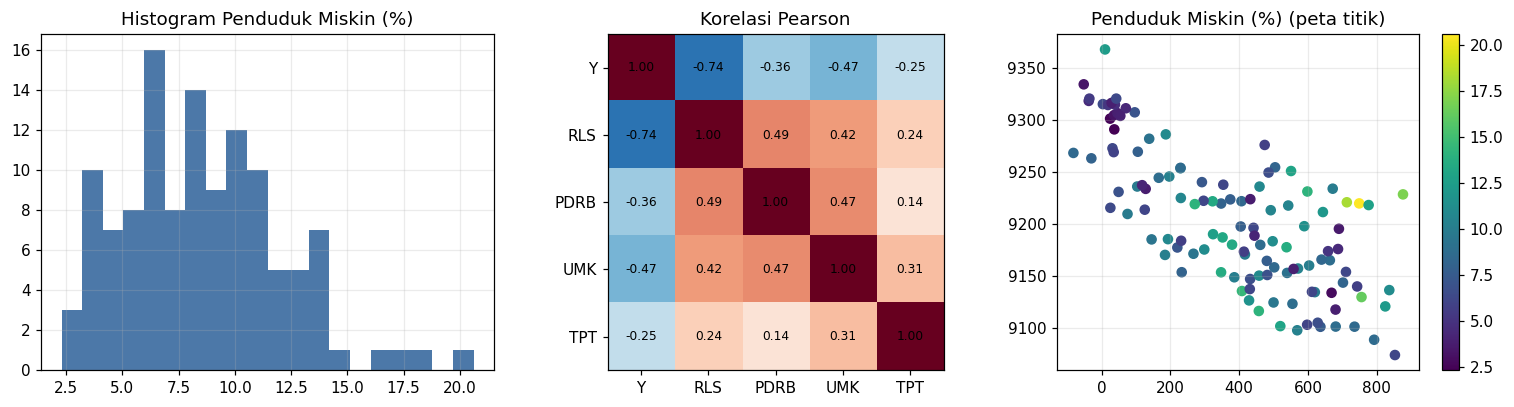

In [20]:
print('Skewness :', df[[Y_COL] + X_COLS].apply(stats.skew).round(2).to_dict())
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].hist(y, bins=20, color='#4C78A8'); ax[0].set_title('Histogram ' + Y_LABEL)
cm = np.corrcoef(np.column_stack([y, Xraw]).T); lab = ['Y'] + X_COLS
im = ax[1].imshow(cm, cmap='RdBu_r', vmin=-1, vmax=1); ax[1].set_xticks(range(5)); ax[1].set_xticklabels(lab); ax[1].set_yticks(range(5)); ax[1].set_yticklabels(lab)
for i in range(5):
    for j in range(5): ax[1].text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=8)
ax[1].set_title('Korelasi Pearson'); ax[1].grid(False)
sc = ax[2].scatter(df.x_km, df.y_km, c=y, cmap='viridis', s=35); plt.colorbar(sc, ax=ax[2]); ax[2].set_title(Y_LABEL + ' (peta titik)')
plt.tight_layout(); plt.show()

## 4. Fungsi bantu (Moran's I, VIF, kernel)

In [21]:
# Matriks bobot spasial untuk Moran's I: k tetangga terdekat, row-standardized
Wm = np.zeros((n, n))
for i in range(n): Wm[i, np.argsort(Dm[i])[1:K_NEIGH + 1]] = 1
W = Wm / Wm.sum(1, keepdims=True)

def moran_perm(z, nperm=NPERM, seed=1):
    rng = np.random.default_rng(seed)
    f = lambda v: ((v - v.mean()) @ W @ (v - v.mean())) / ((v - v.mean()) @ (v - v.mean()))
    obs = f(z); sims = np.array([f(rng.permutation(z)) for _ in range(nperm)])
    return obs, (np.sum(np.abs(sims - sims.mean()) >= abs(obs - sims.mean())) + 1) / (nperm + 1)

def vif_table(A, cols):
    out = {}
    for j, c in enumerate(cols):
        oth = np.column_stack([np.ones(len(A)), np.delete(A, j, axis=1)])
        b = np.linalg.lstsq(oth, A[:, j], rcond=None)[0]
        r2 = 1 - ((A[:, j] - oth @ b) ** 2).sum() / ((A[:, j] - A[:, j].mean()) ** 2).sum()
        out[c] = 1 / (1 - r2)
    return pd.Series(out, name='VIF')

def kernel_bisq(Dp, bw):                        # bisquare adaptif: bw = jumlah tetangga
    h = np.sort(Dp, axis=1)[:, int(min(bw, Dp.shape[0] - 1))][:, None]
    return np.where(Dp < h, (1 - (Dp / h) ** 2) ** 2, 0.0)

## 3a. Uji asumsi 1: multikolinearitas

In [22]:
vif = vif_table(Xraw, X_COLS)
ev = np.linalg.eigvalsh(np.corrcoef(Xraw.T)); cond = np.sqrt(ev.max() / ev.min())
print(vif.round(2).to_string()); print('Condition index =', round(cond, 2), '(aman bila < 30)')
print('Kesimpulan:', 'tidak ada multikolinearitas serius' if vif.max() < 5 else 'ada multikolinearitas (VIF >= 5), pertimbangkan seleksi/penalti')

RLS     1.43
PDRB    1.49
UMK     1.45
TPT     1.13
Condition index = 2.11 (aman bila < 30)
Kesimpulan: tidak ada multikolinearitas serius


## 3b. OLS hanya untuk uji asumsi galat (normalitas, homoskedastisitas, pencilan)

OLS  R2 = 0.578 | adj R2 = 0.564
             koef      SE        t       p
Intercept  8.5582  0.2127  40.2279  0.0000
RLS       -2.3816  0.2546  -9.3539  0.0000
PDRB       0.2492  0.2595   0.9603  0.3390
UMK       -0.7014  0.2565  -2.7342  0.0073
TPT       -0.1160  0.2257  -0.5140  0.6082

Shapiro-Wilk  W=0.977 p=0.0383 | Jarque-Bera JB=3.79 p=0.1502
Breusch-Pagan  = 13.17 p=0.0105 | Koenker = 12.25 p=0.0156  (df=4)
|r terstudentisasi|>2: 5 (>3: 0) | leverage>2k/n: 7 | Cook>4/n: 6
             Kab     Y  r_stud  leverage  Cook
Kepulauan Seribu 12.37    2.52      0.07  0.09
         Sampang 20.61    2.74      0.06  0.09
          Serang  4.48   -1.93      0.07  0.06
           Tegal  6.16   -2.13      0.05  0.05
       Bangkalan 18.25    2.38      0.04  0.05
     Kulon Progo 14.53    2.64      0.03  0.05
         Sumenep 17.02    1.79      0.05  0.03
          Bantul 11.54    1.87      0.03  0.02


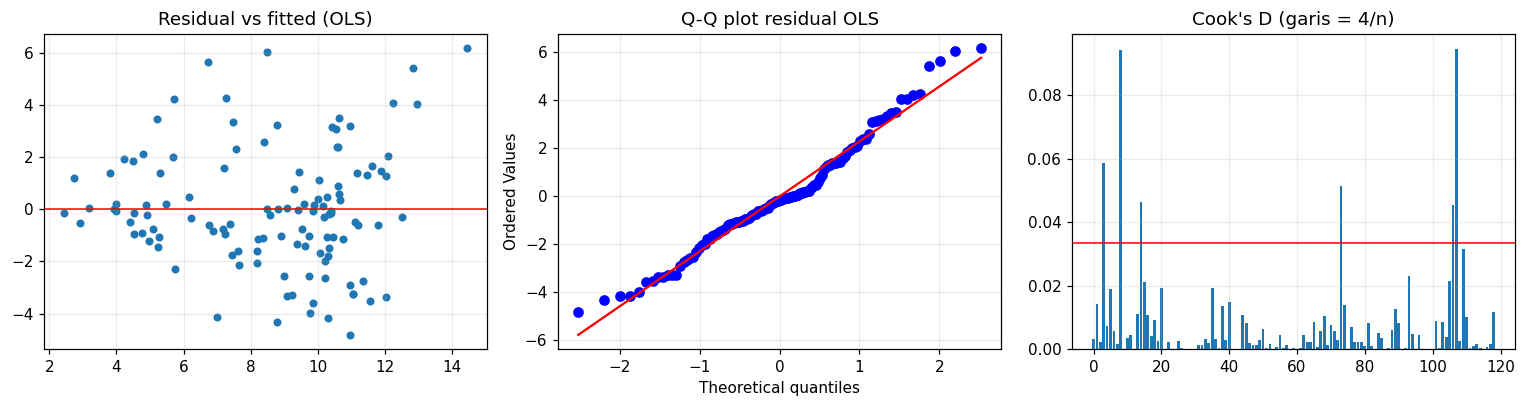

In [23]:
b_ols = np.linalg.solve(X.T @ X, X.T @ y); yhat_ols = X @ b_ols; e_ols = y - yhat_ols
rss_ols = e_ols @ e_ols; s2 = rss_ols / (n - k); XtXi = np.linalg.inv(X.T @ X)
se = np.sqrt(s2 * np.diag(XtXi)); tval = b_ols / se; pval = 2 * (1 - stats.t.cdf(np.abs(tval), n - k))
print('OLS  R2 = %.3f | adj R2 = %.3f' % (1 - rss_ols / tss, 1 - (rss_ols / (n - k)) / (tss / (n - 1))))
print(pd.DataFrame({'koef': b_ols, 'SE': se, 't': tval, 'p': pval}, index=names).round(4).to_string())

# Normalitas galat
sw = stats.shapiro(e_ols); jb = stats.jarque_bera(e_ols)
print('\nShapiro-Wilk  W=%.3f p=%.4f | Jarque-Bera JB=%.2f p=%.4f' % (sw.statistic, sw.pvalue, jb.statistic, jb.pvalue))

# Homoskedastisitas: Breusch-Pagan dan Koenker
u = e_ols ** 2; gg = u / u.mean()
bg = np.linalg.lstsq(X, gg, rcond=None)[0]; bp = ((X @ bg - gg.mean()) ** 2).sum() / 2
bu = np.linalg.lstsq(X, u, rcond=None)[0]; kn = n * (1 - ((u - X @ bu) ** 2).sum() / ((u - u.mean()) ** 2).sum())
print('Breusch-Pagan  = %.2f p=%.4f | Koenker = %.2f p=%.4f  (df=%d)' % (bp, 1 - stats.chi2.cdf(bp, k - 1), kn, 1 - stats.chi2.cdf(kn, k - 1), k - 1))

# Pencilan dan pengaruh
h = np.einsum('ij,jk,ik->i', X, XtXi, X); r_stud = e_ols / np.sqrt(s2 * (1 - h)); cook = r_stud ** 2 * h / (k * (1 - h))
print('|r terstudentisasi|>2: %d (>3: %d) | leverage>2k/n: %d | Cook>4/n: %d' % ((abs(r_stud) > 2).sum(), (abs(r_stud) > 3).sum(), (h > 2 * k / n).sum(), (cook > 4 / n).sum()))
inf = pd.DataFrame({'Kab': df['Kabupaten/Kota'], 'Y': y, 'r_stud': r_stud.round(2), 'leverage': h.round(2), 'Cook': cook.round(2)})
display(inf.sort_values('Cook', ascending=False).head(8)) if 'display' in globals() else print(inf.sort_values('Cook', ascending=False).head(8).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].scatter(yhat_ols, e_ols, s=18); ax[0].axhline(0, c='r', lw=1); ax[0].set_title('Residual vs fitted (OLS)')
stats.probplot(e_ols, plot=ax[1]); ax[1].set_title('Q-Q plot residual OLS')
ax[2].bar(range(n), cook); ax[2].axhline(4 / n, c='r', lw=1); ax[2].set_title("Cook's D (garis = 4/n)")
plt.tight_layout(); plt.show()

## 3c. Uji asumsi spasial: autokorelasi (Moran's I)

In [24]:
I_y, p_y = moran_perm(y); I_e, p_e = moran_perm(e_ols)
print("Moran's I  Y          : I=%.3f  p=%.4f" % (I_y, p_y))
print("Moran's I  residual OLS: I=%.3f  p=%.4f" % (I_e, p_e))

Moran's I  Y          : I=0.323  p=0.0010
Moran's I  residual OLS: I=0.219  p=0.0010


## 4. Fungsi MGWR (backfitting, bandwidth per variabel)

In [25]:
def smoother_term(xj, Wk, omega):
    # estimasi lokal satu suku: beta_j(i) = sum_m w_im*omega_m*x_m*z_m / sum_m w_im*omega_m*x_m^2
    Wo = Wk * omega[None, :]; den = Wo @ (xj ** 2) + 1e-12
    C = (Wo * xj[None, :]) / den[:, None]
    return C, xj[:, None] * C                      # C: pemetaan z -> beta_j ; S: pemetaan z -> f_j

def mgwr_fit(ys, Dp, omega=None, bws=None, select=True, n_sel=4, max_iter=100, tol=1e-6):
    omega = np.ones(n) if omega is None else omega
    bw = list(bws) if bws is not None else [60] * k
    XtXiXt = np.linalg.solve(X.T @ X, X.T); In = np.eye(n)
    R = [X[:, [j]] * XtXiXt[[j], :] for j in range(k)]       # inisialisasi dari OLS
    f = X * (XtXiXt @ ys); Cs = [None] * k; Ss = [None] * k; prev = np.inf
    for it in range(max_iter):
        for j in range(k):
            z = ys - f.sum(1) + f[:, j]
            if select and it < n_sel:                          # pilih bandwidth suku j (AICc terbobot)
                best = None
                for b_ in BW_GRID:
                    C_, S_ = smoother_term(X[:, j], kernel_bisq(Dp, b_), omega)
                    r_ = (omega * (z - S_ @ z) ** 2).sum(); tr_ = np.trace(S_)
                    sc = n * np.log(r_ / n) + n * (n + tr_) / (n - 2 - tr_) if n - 2 - tr_ > 0 else np.inf
                    if best is None or sc < best[0]: best = (sc, b_)
                bw[j] = best[1]; Cs[j] = None
            if Cs[j] is None: Cs[j], Ss[j] = smoother_term(X[:, j], kernel_bisq(Dp, bw[j]), omega)
            R[j] = Ss[j] @ (R[j] + In - sum(R)); f[:, j] = Ss[j] @ z
        
        rss = ((ys - f.sum(1)) ** 2).sum()

        if abs(prev - rss) < tol * max(rss, 1e-12):
            converged_inner = True
            break

        prev = rss
    else:
        converged_inner = False

    return dict(
        f=f,
        bws=bw,
        R=R,
        C=Cs,
        omega=omega,
        iters=it + 1,
        converged_inner=converged_inner
    )

def mgwr_coefs(fit, ys):
    In = np.eye(n); Rsum = sum(fit['R'])
    Bm = [fit['C'][j] @ (In - Rsum + fit['R'][j]) for j in range(k)]       # beta_j(i) = Bm[j][i,:] @ y
    return np.column_stack([Bm[j] @ ys for j in range(k)]), Bm

def mgwr_se(fit, ys):                                                       # SE pendekatan (linear smoother)
    _, Bm = mgwr_coefs(fit, ys); In = np.eye(n); IR = In - sum(fit['R']); d1 = np.trace(IR.T @ IR)
    e = ys - fit['f'].sum(1); s2_ = (fit['omega'] * e ** 2).sum() / d1
    return np.column_stack([np.sqrt(s2_ * (Bm[j] ** 2).sum(1)) for j in range(k)])

## 4b. MGWR + M-estimator (robust)

Tiap iterasi: (1) fit MGWR dengan bobot `omega`; (2) hitung residual dan skala MAD `s = 1.4826·median|e − median(e)|`; (3) bobot Huber `omega = min(1, c/|e/s|)` (atau Tukey bisquare); ulangi sampai bobot konvergen. Bandwidth dipilih ulang pada dua iterasi pertama lalu dikunci.

In [26]:

def robust_mgwr(ys, Dp, kind='huber', c=None,
                max_outer=100, tol=1e-4):

    c = c if c is not None else (
        C_HUBER if kind == 'huber' else 4.685
    )

    omega = np.ones(n)
    bws = None
    delta_history = []
    converged_outer = False
    stop_reason = "Mencapai batas iterasi"

    for it in range(max_outer):
        fit = mgwr_fit(
            ys, Dp, omega, bws,
            select=(it < 2)
        )
        bws = fit['bws']

        e = ys - fit['f'].sum(axis=1)
        s = 1.4826 * np.median(
            np.abs(e - np.median(e))
        )

        if not np.isfinite(s) or s <= 1e-12:
            stop_reason = "Skala residual tidak valid"
            break

        new_omega = psi_weights(e / s, kind, c)
        delta = np.max(np.abs(new_omega - omega))
        delta_history.append(delta)
        omega = new_omega

        if delta < tol and it >= 2:
            converged_outer = True
            stop_reason = "Perubahan bobot di bawah toleransi"
            break

    # Estimasi akhir dengan bobot robust terakhir
    fit = mgwr_fit(
        ys, Dp, omega, bws, select=False
    )

    fit['omega'] = omega
    fit['outer'] = len(delta_history)
    fit['converged_outer'] = converged_outer
    fit['stop_reason'] = stop_reason
    fit['delta_history'] = delta_history
    fit['last_delta'] = (
        delta_history[-1] if delta_history else np.nan
    )

    return fit


fit_rob = robust_mgwr(y, Dm, 'huber'); yhat_rob = fit_rob['f'].sum(1); enp_rob = np.trace(sum(fit_rob['R'])); w_rob = fit_rob['omega']
fit_tuk = robust_mgwr(y, Dm, 'tukey'); yhat_tuk = fit_tuk['f'].sum(1); enp_tuk = np.trace(sum(fit_tuk['R'])); w_tuk = fit_tuk['omega']


for label, fit in [
    ("Huber", fit_rob),
    ("Tukey", fit_tuk)
]:
    print(f"\nKonvergensi MGWR robust {label}")
    print("Konvergen luar :", fit['converged_outer'])
    print("Alasan berhenti:", fit['stop_reason'])
    print("Iterasi luar   :", fit['outer'])
    print("Delta terakhir:", fit['last_delta'])
    print("Konvergen dalam:", fit['converged_inner'])
    print("Iterasi dalam  :", fit['iters'])


print('MGWR robust (Huber): bandwidth', dict(zip(names, fit_rob['bws'])), '| ENP = %.1f | iterasi luar = %d' % (enp_rob, fit_rob['outer']))
print('MGWR robust (Tukey): bandwidth', dict(zip(names, fit_tuk['bws'])), '| ENP = %.1f | iterasi luar = %d' % (enp_tuk, fit_tuk['outer']))
print('Observasi dengan bobot Huber < 0.5: %d | bobot Tukey = 0: %d' % ((w_rob < .5).sum(), (w_tuk == 0).sum()))


Konvergensi MGWR robust Huber
Konvergen luar : True
Alasan berhenti: Perubahan bobot di bawah toleransi
Iterasi luar   : 10
Delta terakhir: 4.344625150143333e-05
Konvergen dalam: True
Iterasi dalam  : 27

Konvergensi MGWR robust Tukey
Konvergen luar : True
Alasan berhenti: Perubahan bobot di bawah toleransi
Iterasi luar   : 24
Delta terakhir: 7.108795882226904e-05
Konvergen dalam: True
Iterasi dalam  : 28
MGWR robust (Huber): bandwidth {'Intercept': 15, 'RLS': 100, 'PDRB': 119, 'UMK': 119, 'TPT': 119} | ENP = 26.1 | iterasi luar = 10
MGWR robust (Tukey): bandwidth {'Intercept': 15, 'RLS': 80, 'PDRB': 119, 'UMK': 119, 'TPT': 119} | ENP = 26.3 | iterasi luar = 24
Observasi dengan bobot Huber < 0.5: 5 | bobot Tukey = 0: 0


## 5. Ringkasan model MGWR robust (Huber utama, Tukey sebagai uji sensitivitas)

In [27]:
core = w_rob >= 0.5                                  # observasi 'inti' (bukan pencilan menurut bobot Huber)
def summarize(label, yhat, enp, bwtxt=''):
    e = y - yhat; rss = e @ e; I_, p_ = moran_perm(e)
    return dict(Model=label, ENP=round(enp, 1), R2=round(1 - rss / tss, 3), RMSE=round(np.sqrt(rss / n), 3), MAE=round(np.abs(e).mean(), 3),
                MedAE=round(np.median(np.abs(e)), 3), RMSE_inti=round(np.sqrt((e[core] ** 2).mean()), 3),
                Moran_I=round(I_, 3), Moran_p=round(p_, 4), Bandwidth=bwtxt)
res_tab = pd.DataFrame([
    summarize('MGWR robust (Huber)', yhat_rob, enp_rob, str(dict(zip(names, fit_rob['bws'])))),
    summarize('MGWR robust (Tukey)', yhat_tuk, enp_tuk, str(dict(zip(names, fit_tuk['bws']))))])
pd.set_option('display.width', 250); pd.set_option('display.max_colwidth', 100)
print(res_tab.to_string(index=False)); res_tab.to_csv(os.path.join(OUT_DIR, 'ringkasan_model_robust.csv'), index=False)
print("\nCatatan: estimasi robust bukan penaksir maksimum likelihood, sehingga AICc tidak dilaporkan; gunakan R2, RMSE, MedAE, RMSE_inti.")
print("RMSE_inti = RMSE pada observasi dengan bobot Huber >= 0.5.")

              Model  ENP    R2  RMSE   MAE  MedAE  RMSE_inti  Moran_I  Moran_p                                                          Bandwidth
MGWR robust (Huber) 26.1 0.783 1.630 1.213  0.911      1.347   -0.075    0.186 {'Intercept': 15, 'RLS': 100, 'PDRB': 119, 'UMK': 119, 'TPT': 119}
MGWR robust (Tukey) 26.3 0.762 1.707 1.224  0.923      1.370   -0.026    0.689  {'Intercept': 15, 'RLS': 80, 'PDRB': 119, 'UMK': 119, 'TPT': 119}

Catatan: estimasi robust bukan penaksir maksimum likelihood, sehingga AICc tidak dilaporkan; gunakan R2, RMSE, MedAE, RMSE_inti.
RMSE_inti = RMSE pada observasi dengan bobot Huber >= 0.5.


## 6. Uji heterogenitas spasial (Monte Carlo) pada MGWR robust (Huber)

In [28]:
def mc_variability(fit, ys, nsim=NSIM_MC, seed=7):
    rng = np.random.default_rng(seed); obs = mgwr_coefs(fit, ys)[0].std(0); sims = np.zeros((nsim, k))
    for s_ in range(nsim):
        pm = rng.permutation(n); f_ = mgwr_fit(ys, Dm[np.ix_(pm, pm)], fit['omega'], fit['bws'], select=False)
        sims[s_] = mgwr_coefs(f_, ys)[0].std(0)
    return pd.DataFrame({'SD_koef_lokal': obs, 'p_MonteCarlo': (1 + (sims >= obs).sum(0)) / (1 + nsim)}, index=names)
mc_tab = mc_variability(fit_rob, y); print(mc_tab.round(4).to_string())
print('p < 0.05 -> koefisien bervariasi secara spasial (nonstasioner); bandwidth besar (mendekati %d) -> efek praktis global.' % n)

           SD_koef_lokal  p_MonteCarlo
Intercept         1.1541          0.01
RLS               0.2162          0.01
PDRB              0.0696          0.13
UMK               0.0519          0.58
TPT               0.0926          0.21
p < 0.05 -> koefisien bervariasi secara spasial (nonstasioner); bandwidth besar (mendekati 119) -> efek praktis global.


## 7. Koefisien lokal, uji-t pendekatan, dan peta

Koefisien lokal MGWR robust (prediktor distandarisasi; satuan = poin persen per 1 SD)
           bandwidth    min    q25  median    q75     max  %negatif  %|t|>1.96
Intercept         15  6.052  7.487   8.031  9.106  11.267     0.000      100.0
RLS              100 -2.722 -2.602  -2.406 -2.148  -2.090   100.000      100.0
PDRB             119  0.005  0.038   0.086  0.183   0.194     0.000        0.0
UMK              119 -0.402 -0.357  -0.290 -0.257  -0.253   100.000        0.0
TPT              119 -0.012  0.062   0.161  0.247   0.264     3.361        0.0


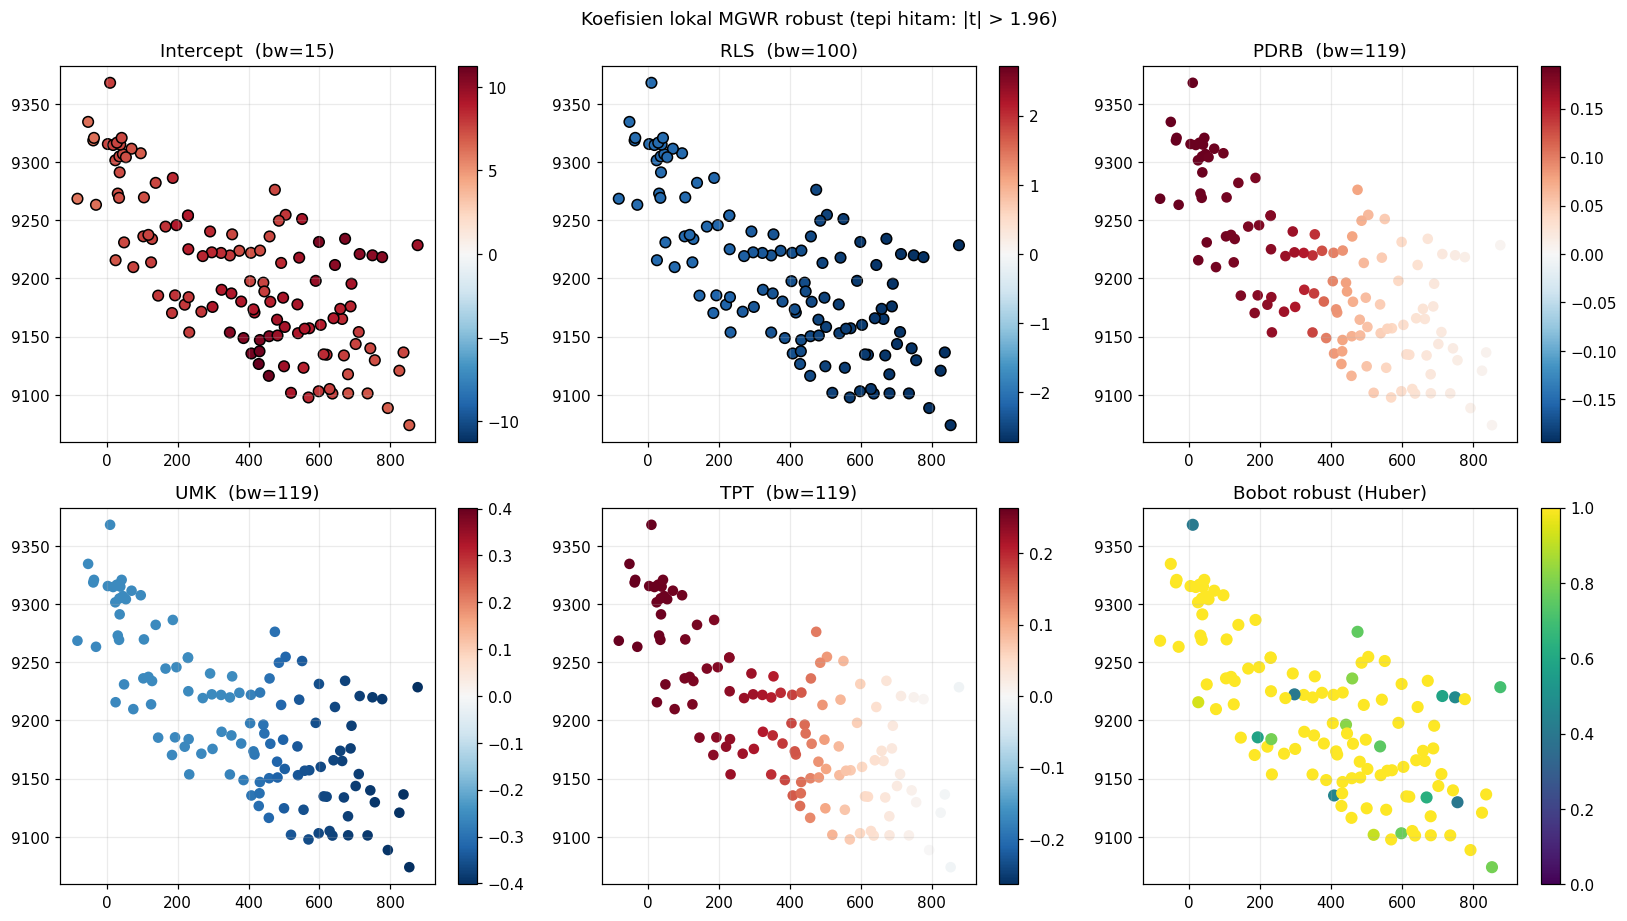

In [29]:
beta, _ = mgwr_coefs(fit_rob, y); se_b = mgwr_se(fit_rob, y); tloc = beta / se_b
summ = pd.DataFrame({'bandwidth': fit_rob['bws'], 'min': beta.min(0), 'q25': np.percentile(beta, 25, 0), 'median': np.median(beta, 0),
                     'q75': np.percentile(beta, 75, 0), 'max': beta.max(0), '%negatif': (beta < 0).mean(0) * 100, '%|t|>1.96': (np.abs(tloc) > 1.96).mean(0) * 100}, index=names)
print('Koefisien lokal MGWR robust (prediktor distandarisasi; satuan = poin persen per 1 SD)'); print(summ.round(3).to_string())

out = df[['Provinsi', 'Kabupaten/Kota', 'x_km', 'y_km']].copy(); out['bobot_robust_Huber'] = w_rob; out['fitted'] = yhat_rob; out['residual'] = y - yhat_rob
for j, nm in enumerate(names): out['b_' + nm] = beta[:, j]; out['t_' + nm] = tloc[:, j]
out.to_csv(os.path.join(OUT_DIR, 'koefisien_lokal_MGWR_robust.csv'), index=False); summ.to_csv(os.path.join(OUT_DIR, 'ringkasan_koefisien.csv'))

fig, axes = plt.subplots(2, 3, figsize=(15, 8.5)); axes = axes.ravel()
for j, nm in enumerate(names):
    lim = np.abs(beta[:, j]).max(); sc = axes[j].scatter(df.x_km, df.y_km, c=beta[:, j], cmap='RdBu_r', vmin=-lim, vmax=lim, s=48, edgecolors=np.where(np.abs(tloc[:, j]) > 1.96, 'k', 'none'))
    axes[j].set_title('%s  (bw=%d)' % (nm, fit_rob['bws'][j])); plt.colorbar(sc, ax=axes[j])
sc = axes[5].scatter(df.x_km, df.y_km, c=w_rob, cmap='viridis', s=48, vmin=0, vmax=1); axes[5].set_title('Bobot robust (Huber)'); plt.colorbar(sc, ax=axes[5])
fig.suptitle('Koefisien lokal MGWR robust (tepi hitam: |t| > 1.96)'); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'peta_koefisien.png')); plt.show()

## 8. Diagnostik akhir dan daftar pencilan

Residual MGWR robust: Shapiro p=0.0170 | Moran I=-0.075 (p=0.1860)


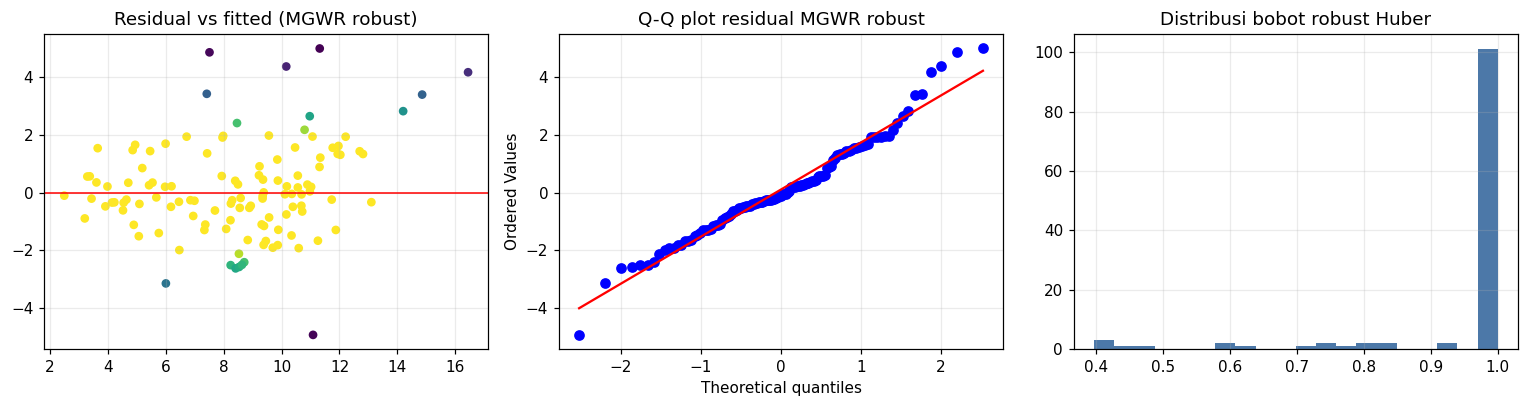


Observasi yang diturunkan bobotnya (Huber < 0.7):
       Provinsi         Kab/Kota     Y  fitted_robust  residual  bobot_Huber  bobot_Tukey
    Jawa Tengah            Tegal  6.16          11.09     -4.93         0.40         0.09
     Jawa Timur      Probolinggo 16.31          11.32      4.99         0.40         0.06
    DKI Jakarta Kepulauan Seribu 12.37           7.51      4.86         0.41         0.06
D.I. Yogyakarta      Kulon Progo 14.53          10.16      4.37         0.45         0.19
     Jawa Timur          Sampang 20.61          16.44      4.17         0.48         0.17
     Jawa Barat Kota Tasikmalaya 10.84           7.42      3.42         0.58         0.49
     Jawa Timur        Bangkalan 18.25          14.86      3.39         0.58         0.39
     Jawa Timur        Kota Batu  2.86           6.01     -3.15         0.63         0.55


In [30]:
e_rob = y - yhat_rob
print('Residual MGWR robust: Shapiro p=%.4f | Moran I=%.3f (p=%.4f)' % (stats.shapiro(e_rob).pvalue, *moran_perm(e_rob)))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].scatter(yhat_rob, e_rob, c=w_rob, cmap='viridis', s=22); ax[0].axhline(0, c='r', lw=1); ax[0].set_title('Residual vs fitted (MGWR robust)')
stats.probplot(e_rob, plot=ax[1]); ax[1].set_title('Q-Q plot residual MGWR robust')
ax[2].hist(w_rob, bins=20, color='#4C78A8'); ax[2].set_title('Distribusi bobot robust Huber')
plt.tight_layout(); plt.show()
flag = pd.DataFrame({'Provinsi': df.Provinsi, 'Kab/Kota': df['Kabupaten/Kota'], 'Y': y, 'fitted_robust': yhat_rob.round(2), 'residual': e_rob.round(2), 'bobot_Huber': w_rob.round(2), 'bobot_Tukey': w_tuk.round(2)})
flag = flag[flag.bobot_Huber < 0.7].sort_values('bobot_Huber'); print('\nObservasi yang diturunkan bobotnya (Huber < 0.7):'); print(flag.to_string(index=False))
flag.to_csv(os.path.join(OUT_DIR, 'daftar_pencilan.csv'), index=False)

## Cara membaca hasil / kerangka pelaporan
1. **Asumsi:** laporkan VIF, Shapiro/JB, BP/Koenker, Cook's D, Moran's I (bagian 3).
2. **Mengapa MGWR:** uji Monte Carlo dan bandwidth per variabel menunjukkan variabel mana yang bervariasi secara spasial (bagian 4 dan 6).
3. **Mengapa robust:** residual tidak sepenuhnya normal / ada pencilan, dan bobot robust menandai observasi yang diturunkan pengaruhnya (bagian 3, 5, 8).
4. **Skala proses:** bandwidth kecil = variasi lokal; bandwidth mendekati N = efek praktis global.
5. **Interpretasi koefisien:** per 1 SD prediktor, perubahan persen miskin = koefisien lokal; tanda berubah antarwilayah menunjukkan pengaruh yang berbeda. Uji-t lokal hanya pendekatan.